# 6장 — TD(0) Prediction과 Q-learning

같은 Episode에서 MC와 TD의 학습 입력 차이를 확인하고 Q-learning으로 정책을 개선한다.
`TabularTD0PredictionLearner`와 `TabularQLearner`를 사용한다.

[원본 Notebook](https://github.com/WegraLee/deep-learning-from-scratch-4/blob/b82cd6432b4e63ce6a4ab2b925fc74a1227fb06a/notebooks/06_temporal_difference.ipynb) · [실습 대응표](README.md)
SARSA와 Off-policy SARSA는 미구현이다. Notebook 내부에 대신 구현하지 않는다.

## 1. Import와 설정

In [1]:
%matplotlib inline
import numpy as np
import torch
import matplotlib.pyplot as plt

from modular_rl.data import Transition
from modular_rl.model import Model
from modular_rl.component.representation import IdentityRepresentation
from modular_rl.component.estimator import TabularVEstimator, TabularQEstimator
from modular_rl.component.action_selector import EpsilonGreedyActionSelector, GreedyActionSelector
from modular_rl.component.target_generator import TD0TargetGenerator, MonteCarloReturnGenerator
from modular_rl.component.update_rule import TabularVUpdateRule, TabularQUpdateRule
from modular_rl.learner import TabularTD0PredictionLearner, TabularQLearner, MCPredictionLearner
from modular_rl.environment import dlfs4_gridworld, DLFS4_STATES, DLFS4_START_STATE, TabularEpisodeSampler
from modular_rl.dp import uniform_policy, policy_evaluation
from plotting import plot_grid

SEED, GAMMA, ALPHA, EPISODES = 7, 0.9, 0.01, 1000
torch.manual_seed(SEED)
plt.close('all')

## 2. TD(0) 한 번의 계산 — `td_eval.py`

$$y=r+\gamma(1-\text{terminated})V(s'),\quad\delta=y-V(s),\quad V(s)\leftarrow V(s)+\alpha\delta$$

V(1)=4, V(2)=10, r=1, γ=.9, α=.5이면 y=10, δ=6, 새 V(1)=7이다.
Target 생성과 갱신은 기존 Component가 계산한다. `Transition.to_batch()`으로 B=1로 변환한다.

In [2]:
demo_model = Model(IdentityRepresentation(), TabularVEstimator(3)).double()
demo_model.estimator.v_table.copy_(torch.tensor([0., 4., 10.]))
demo_td = TabularTD0PredictionLearner(demo_model, TD0TargetGenerator(.9), TabularVUpdateRule(.5))
delta = demo_td.learn(Transition(1, 0, 1., 2, False, False).to_batch())
assert delta.item() == 6 and demo_model.forward(1).values.v.item() == 7
print('signed TD error:', delta.item(), '| updated V(1):', demo_model.forward(1).values.v.item())

signed TD error: 6.0 | updated V(1): 7.0


## 3. 교재 환경과 독립적인 MC / TD Model

원본처럼 시작 `(2,0)`, Uniform Policy, γ=.9, α=.01, 1,000 Episode를 사용한다.
MC와 TD는 각기 다른 V를 갖는다. 둘 다 동일한 DP Vπ를 기준으로 비교한다.

In [3]:
mdp = dlfs4_gridworld()
states = np.arange(mdp.n_states)
nonterminal = np.setdiff1d(states, mdp.terminal_states)
policy = uniform_policy(mdp)
reference = policy_evaluation(mdp, policy, gamma=GAMMA, theta=1e-10)
assert reference.converged
sampler = TabularEpisodeSampler(mdp, policy, seed=SEED)
mc_model = Model(IdentityRepresentation(), TabularVEstimator(mdp.n_states)).double()
td_model = Model(IdentityRepresentation(), TabularVEstimator(mdp.n_states)).double()
mc = MCPredictionLearner(mc_model, MonteCarloReturnGenerator(GAMMA), visit_mode='every')
td = TabularTD0PredictionLearner(td_model, TD0TargetGenerator(GAMMA), TabularVUpdateRule(ALPHA))

## 4. 같은 Episode 학습 — MC는 전체, TD는 전이별

MC는 완료 Episode의 Return을 사용한다. TD는 전이를 시간 순서대로 B=1로 전달해 갱신한다.
여기서는 비교를 위해 이미 수집된 Episode를 처리한다. 환경 종료 전에 학습하는 Streaming Runner는 아니다.
잘린 Episode는 MC에 사용할 수 없으므로 비교 자체를 중단한다.

In [4]:
history, steps = [], 0
for number in range(1, EPISODES + 1):
    episode = sampler.sample(DLFS4_START_STATE, max_steps=2000)
    if not episode.terminated:
        raise RuntimeError('Incomplete comparison episode: MC must not learn a partial return')
    mc.learn(episode)
    for transition in episode.transitions:
        td.learn(transition.to_batch())
    steps += len(episode)
    if number % 100 == 0:
        values = [model.forward(states).values.v.numpy() for model in (mc_model, td_model)]
        errors = [np.sqrt(np.mean((v[nonterminal] - reference.values[nonterminal]) ** 2)) for v in values]
        history.append((number, steps, *errors))
print(f'episodes={EPISODES} steps={steps} seed={SEED} gamma={GAMMA} alpha={ALPHA}')
print('RMSE(MC, TD):', np.round(errors, 4))

episodes=1000 steps=43598 seed=7 gamma=0.9 alpha=0.01
RMSE(MC, TD): [0.0238 0.0371]


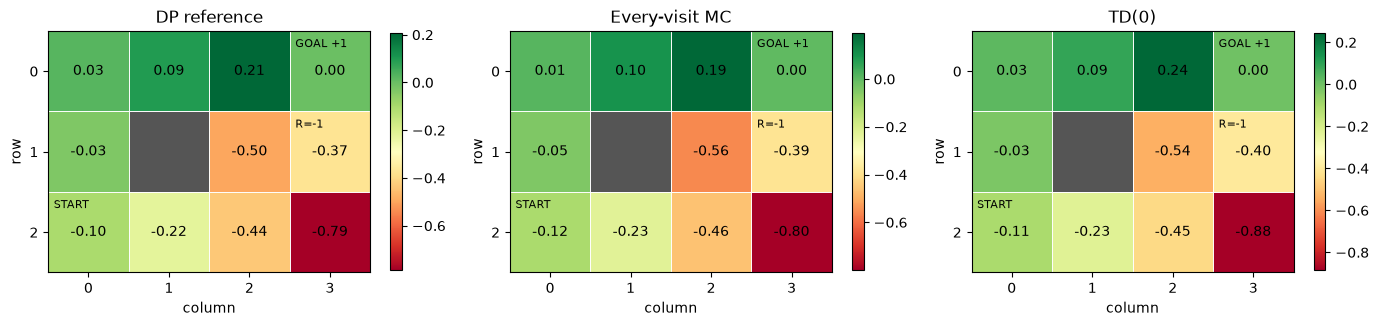

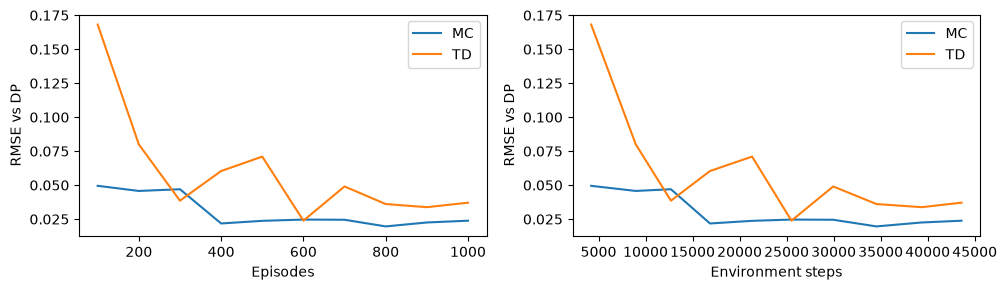

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, title, value in zip(axes, ('DP reference', 'Every-visit MC', 'TD(0)'), (reference.values, *values)):
    plot_grid(value, title=title, ax=ax)
plt.tight_layout(); plt.show()
history = np.array(history)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for column, label in ((2, 'MC'), (3, 'TD')):
    axes[0].plot(history[:, 0], history[:, column], label=label)
    axes[1].plot(history[:, 1], history[:, column], label=label)
axes[0].set(xlabel='Episodes', ylabel='RMSE vs DP')
axes[1].set(xlabel='Environment steps', ylabel='RMSE vs DP')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

## 5. B=1 Online와 B>1 Frozen Target Batch

`learn(batch)`는 **모든 Bootstrap Target을 갱신 전에 계산**한다. B>1에서 같은 상태가 반복되면
현재 V는 행 순서대로 갱신되지만 Target을 행 사이에 다시 계산하지 않는다.
위처럼 B=1로 호출하면 다음 전이의 Target은 이전 갱신을 반영한다.

예를 들어 V(1)=4, V(2)=10, γ=.9, α=.5이고 `(state,reward,next_state)`가 `(2,0,1)`, `(1,1,2)`이면
Batch의 error는 `[-6.4,6]`, 전이별 호출은 `[-6.4,3.12]`다. 두 계약은 회귀 테스트로 검증한다.

TD는 일반적인 Time-limit `truncated=True, terminated=False`에서 Bootstrap을 유지한다.
수집자가 reset된 관측 대신 실제 마지막 관측을 전달해야 한다. MC의 미완성 Episode 거절과 구분한다.
고정 α의 TD 오차와 표본 평균 MC 오차가 매 구간 감소하거나 특정 방법이 항상 우수할 필요는 없다.

## 6. SARSA — 미구현 대응

원본 [`sarsa.py`](https://github.com/WegraLee/deep-learning-from-scratch-4/blob/b82cd6432b4e63ce6a4ab2b925fc74a1227fb06a/ch06/sarsa.py)는 실제 다음 행동의 Q(s′,a′)로 Bootstrap한다.
γ=.9, α=.8, ε=.1, 10,000 Episode이며 `SarsaAgent`는 길이 2의 deque를 사용한다.
현재 TransitionBatch에 next_action이 없으므로 수집한 실제 다음 행동을 명시적으로 전달하는 계약과
작은 SARSA Learner가 필요하다. 현재 Q-learning을 SARSA로 부르거나 선택 행동을 추측하지 않는다.

## 7. Off-policy SARSA — 미구현 대응

원본 [`sarsa_off_policy.py`](https://github.com/WegraLee/deep-learning-from-scratch-4/blob/b82cd6432b4e63ce6a4ab2b925fc74a1227fb06a/ch06/sarsa_off_policy.py)는 target/behavior 정책의 비율로
TD Target을 보정한다(γ=.9, α=.8, ε=.1, 10,000 Episode).
행동 확률의 저장 시점과 보정 규칙을 포함한 별도 Learner 계약이 필요하다. 이 실습은 실행 지원하지 않는다.

## 8. Q-learning — `q_learning.py`

$$y=r+\gamma(1-\text{terminated})\max_aQ(s',a)$$

행동 선택은 ε-greedy `Model.act()`, 학습은 `TabularQLearner.learn()`가 담당한다.
고정 정책의 V Prediction과 달리 Q에서 학습 중의 정책을 개선한다.

In [6]:
q_model = Model(IdentityRepresentation(), TabularQEstimator(mdp.n_states, mdp.n_actions),
                EpsilonGreedyActionSelector(epsilon=.1)).double()
q_learner = TabularQLearner(q_model, TD0TargetGenerator(GAMMA), TabularQUpdateRule(alpha=.8))
Q_EPISODES, MAX_STEPS = 1000, 200

교재 MDP는 결정적이므로 각 행동의 유일한 Outcome을 사용한다. 환경 진행은 아래 루프가 담당하고
학습 수식은 Learner가 담당한다. 원본의 10,000 Episode 대신 간소화 예제와 같은 1,000 Episode로 실행한다.

In [7]:
reward_history, truncated_episodes = [], 0
for number in range(Q_EPISODES):
    state, total_reward = DLFS4_START_STATE, 0.
    for step in range(MAX_STEPS):
        selected = q_model.act(state)
        action = selected.action.item()
        outcome = mdp.transitions[state][action][0]
        truncated = step + 1 == MAX_STEPS and not outcome.terminated
        transition = Transition(state, action, outcome.reward, outcome.next_state,
                                outcome.terminated, truncated, selected.log_prob)
        q_learner.learn(transition.to_batch())
        state = outcome.next_state
        total_reward += outcome.reward
        if transition.terminated or transition.truncated:
            break
    truncated_episodes += int(truncated)
    reward_history.append(total_reward)
print(f'Q-learning: episodes={Q_EPISODES} seed={SEED} gamma={GAMMA} alpha=.8 epsilon=.1')
print('truncated:', truncated_episodes, '| last 100 mean reward:', np.mean(reward_history[-100:]))

Q-learning: episodes=1000 seed=7 gamma=0.9 alpha=.8 epsilon=.1
truncated: 0 | last 100 mean reward: 1.0


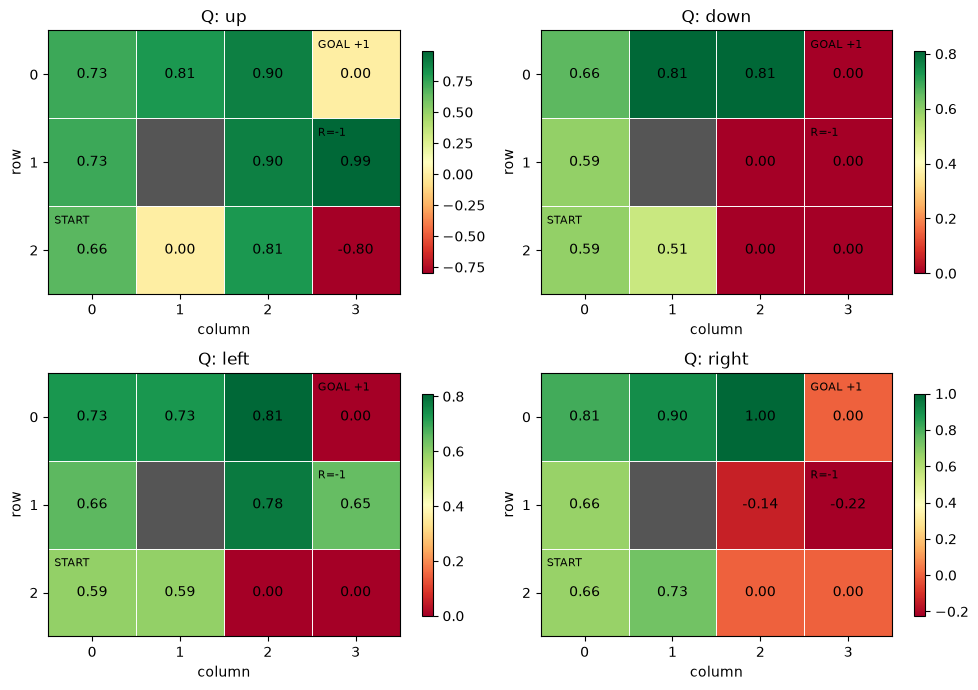

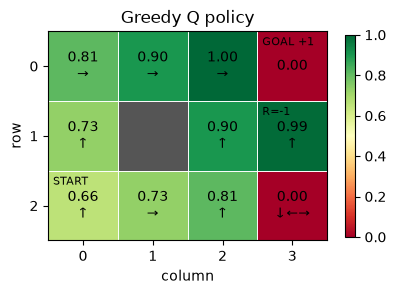

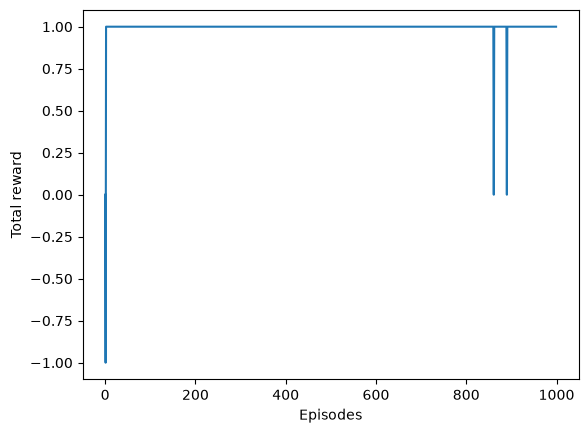

In [8]:
estimate = q_model.forward(states)
q_values = estimate.values.q[0].numpy()
greedy_policy = GreedyActionSelector().probabilities(estimate).numpy()
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for action, ax in enumerate(axes.flat):
    plot_grid(q_values[:, action], title=f'Q: {("up", "down", "left", "right")[action]}', ax=ax)
plt.tight_layout(); plt.show()
plot_grid(q_values.max(axis=-1), greedy_policy, title='Greedy Q policy')
plt.show()
plt.plot(reward_history)
plt.xlabel('Episodes'); plt.ylabel('Total reward'); plt.show()

## 9. Greedy Policy를 실행해 확인

In [9]:
state, path = DLFS4_START_STATE, [DLFS4_STATES[DLFS4_START_STATE]]
for _ in range(20):
    action = q_model.act(state, deterministic=True).action.item()
    outcome = mdp.transitions[state][action][0]
    state = outcome.next_state
    path.append(DLFS4_STATES[state])
    if outcome.terminated:
        break
print('greedy path:', path, '| reached goal:', outcome.terminated)

greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)] | reached goal: True


## 10. `q_learning_simple.py`와의 대응

원본 두 Q-learning 예제의 업데이트는 같다. 위 Model + Learner가 두 예제를 함께 대체하므로
같은 학습 루프를 다시 복사하지 않는다. `Model.act()`는 행동과 Behavior log_prob를 함께 반환한다.
ModularRL의 학습 모드에서는 최대 Q 동률에 균등하게 탐색 확률을 주고 deterministic 모드는
가장 작은 인덱스를 택한다. 원본의 간소화 버전은 np.argmax로 첫 행동을 택한다.

SARSA·Off-policy SARSA의 미구현을 포함한 전체 대응 상태는 README 표에 기록했다.

고정 시작에서 방문이 적은 상태·행동의 Q는 0으로 남을 수 있다. 경로 성공이 모든 Q의 수렴을 뜻하지 않는다.